# Bioreaction Data Exploration

---
### Project Overview
This dataset comes from a **fed-batch bioreactor process**. The goal is to predict **4 target variables** — `vcd` (viable cell density), `tcd` (total cell density), `substrate`, and `byproduct` — across 12 test batches where only `elapsed_time` and `volume` are known.

### Data Summary
- **2,858 rows** across **61 batches** (Batch1–Batch61)
- **12 columns**: batch metadata, time, 4 target measurements, 4 feed inputs, volume, and prediction flag
- Data is **sparse** — measurements and feed events are on **separate, interleaved rows** (not a dense matrix)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook', palette='Set2')
%matplotlib inline

DATA_PATH = '/home/renku/work/input-data/Project 1 - DTB/bioreaction_remaining.csv'

In [16]:
df_raw = pd.read_csv(DATA_PATH)
print(f'Shape: {df_raw.shape}')
print(f'Batches: {df_raw["batch_id"].nunique()}')
df_raw.head(15)

Shape: (2858, 12)
Batches: 61


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False
8,Batch1,3.501829,NaN,NaN,NaN,NaN,NaN,NaN,0.000863,NaN,NaN,False
9,Batch1,3.970833,14.300371,14.405872,2.263021,2.301048,NaN,NaN,NaN,NaN,10.946566,False


---
## 1. Data Structure & Sparsity

The data rows are **heterogeneous**: each row only populates a subset of columns. Core measurements (vcd, tcd, substrate, byproduct) appear on one set of rows, while feed events (feed_substrate, feed_b, feed_c, feed_d) appear on separate rows at different timestamps.

In [17]:
# Non-null counts reveal the sparsity pattern
non_null = df_raw.notnull().sum().sort_values(ascending=False)
non_null_df = pd.DataFrame({'column': non_null.index, 'non_null_count': non_null.values, 
                             'pct': (non_null.values / len(df_raw) * 100).round(1)})
non_null_df

,column,non_null_count,pct
0,batch_id,2858,100.0
1,elapsed_time,2858,100.0
2,to_predict,2858,100.0
3,feed_c,957,33.5
4,volume,854,29.9
5,feed_b,732,25.6
6,tcd,698,24.4
7,vcd,698,24.4
8,substrate,698,24.4
9,byproduct,698,24.4


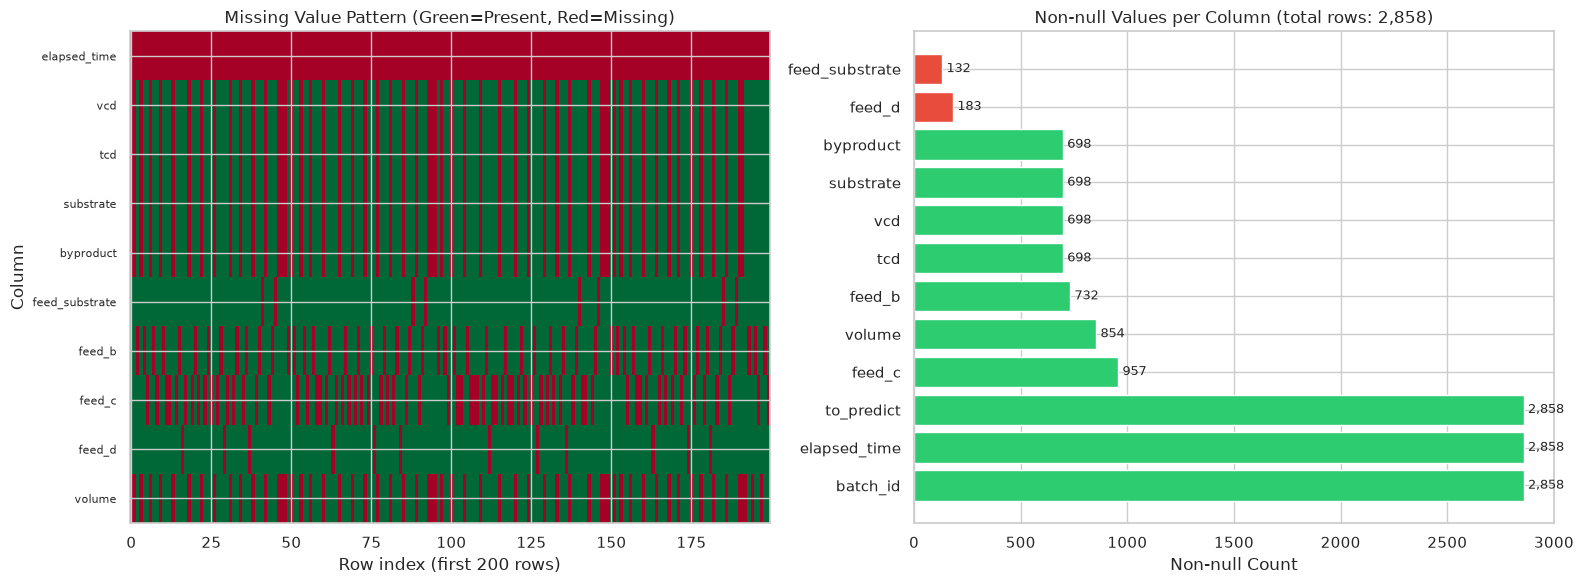

In [18]:
# Visual sparsity pattern (sample of rows across batches)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Full dataset sparsity
missing = df_raw.drop(columns=['batch_id', 'to_predict']).isnull().astype(int)
ax = axes[0]
im = ax.imshow(missing.T.iloc[:, :200], aspect='auto', cmap='RdYlGn', vmin=0, vmax=1,
               interpolation='nearest')
ax.set_xlabel('Row index (first 200 rows)')
ax.set_ylabel('Column')
ax.set_yticks(range(len(missing.columns)))
ax.set_yticklabels(missing.columns, fontsize=8)
ax.set_title('Missing Value Pattern (Green=Present, Red=Missing)')

# Bar chart
ax = axes[1]
colors = ['#2ecc71' if v > 500 else '#e74c3c' if v < 200 else '#f39c12' 
          for v in non_null.values]
bars = ax.barh(non_null.index, non_null.values, color=colors)
ax.set_xlabel('Non-null Count')
ax.set_title('Non-null Values per Column (total rows: {:,})'.format(len(df_raw)))
for bar, val in zip(bars, non_null.values):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, 
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

---
## 2. Train / Prediction Split

The `to_predict` column flags which rows are prediction targets:
- **`False` (2,702 rows)**: Training data — core measurements are populated
- **`True` (156 rows)**: Prediction targets — only `elapsed_time` and `volume` are known; `vcd`, `tcd`, `substrate`, `byproduct` must be predicted

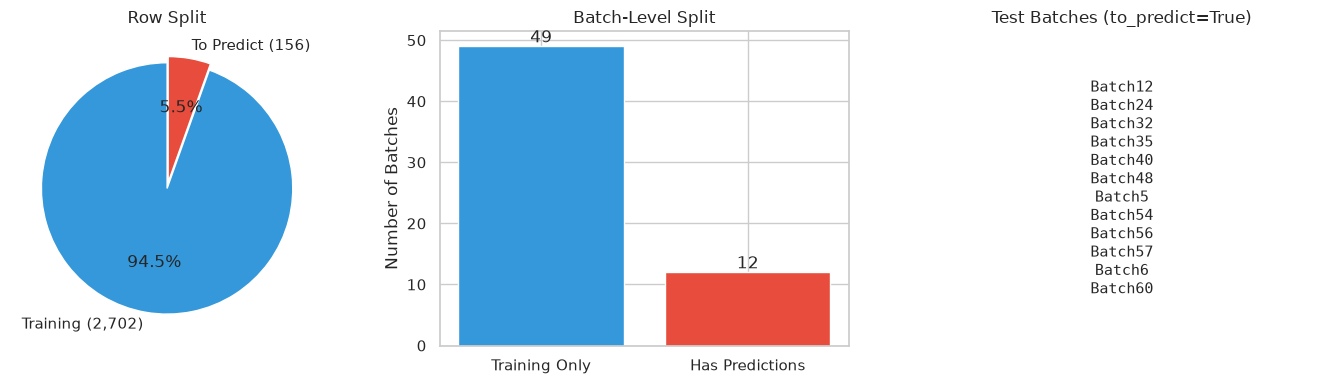

In [19]:
# Split overview
train_mask = df_raw['to_predict'] == False
predict_mask = df_raw['to_predict'] == True

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Pie chart
counts = [train_mask.sum(), predict_mask.sum()]
labels = [f'Training ({counts[0]:,})', f'To Predict ({counts[1]:,})']
axes[0].pie(counts, labels=labels, autopct='%1.1f%%', explode=(0, 0.05),
            colors=['#3498db', '#e74c3c'], startangle=90)
axes[0].set_title('Row Split')

# Batch-level split
batch_labels = df_raw.groupby('batch_id')['to_predict'].any()
train_batches = (batch_labels == False).sum()
predict_batches = (batch_labels == True).sum()
axes[1].bar(['Training Only', 'Has Predictions'], [train_batches, predict_batches],
           color=['#3498db', '#e74c3c'])
axes[1].set_ylabel('Number of Batches')
axes[1].set_title('Batch-Level Split')
axes[1].bar_label(axes[1].containers[0])

# Which batches have predictions
predict_batch_ids = sorted(df_raw[predict_mask]['batch_id'].unique())
axes[2].text(0.5, 0.5, '\n'.join(predict_batch_ids), ha='center', va='center',
            fontsize=11, fontfamily='monospace')
axes[2].set_title('Test Batches (to_predict=True)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [20]:
# What data is available in prediction rows?
predict_df = df_raw[predict_mask]
print('Columns available in prediction rows:')
print(predict_df.notnull().sum()[predict_df.notnull().sum() > 0].to_string())
print(f'\nPrediction rows per batch:')
print(predict_df['batch_id'].value_counts().sort_index().to_string())

Columns available in prediction rows:
batch_id        156
elapsed_time    156
volume          156
to_predict      156

Prediction rows per batch:
batch_id
Batch12    13
Batch24    13
Batch32    13
Batch35    13
Batch40    13
Batch48    13
Batch5     13
Batch54    13
Batch56    13
Batch57    13
Batch6     13
Batch60    13


---
## 3. Batch-Level Exploration

Each batch is a time-series. Let's inspect individual batches to understand the trajectory shapes and data availability.

In [21]:
# Per-batch statistics
batch_stats = df_raw.groupby('batch_id').agg(
    n_rows=('elapsed_time', 'count'),
    time_start=('elapsed_time', 'min'),
    time_end=('elapsed_time', 'max'),
    time_duration=('elapsed_time', lambda x: x.max() - x.min()),
    n_measurements=('vcd', 'count'),
    n_feeds=('feed_substrate', 'count'),
    volume_start=('volume', 'first'),
    volume_end=('volume', 'last'),
    has_predict=('to_predict', 'any')
).reset_index()

batch_stats['batch_num'] = batch_stats['batch_id'].str.extract(r'(\d+)').astype(int)
batch_stats = batch_stats.sort_values('batch_num')

batch_stats.head(15)

,batch_id,n_rows,time_start,time_end,time_duration,n_measurements,n_feeds,volume_start,volume_end,has_predict,batch_num
0,Batch1,47,0.0,13.000694,13.000694,14,2,10.500750,16.660309,False,1
11,Batch2,47,0.0,12.882639,12.882639,14,2,10.387929,17.037199,False,2
22,Batch3,54,0.0,12.908333,12.908333,14,2,10.390391,16.874251,False,3
33,Batch4,43,0.0,12.870139,12.870139,14,2,10.506364,17.008180,False,4
44,Batch5,43,0.0,12.884028,12.884028,1,2,10.505283,17.181898,True,5
55,Batch6,45,0.0,12.840972,12.840972,1,3,10.397032,16.820895,True,6
58,Batch7,47,0.0,12.880556,12.880556,14,2,10.352277,16.400664,False,7
59,Batch8,44,0.0,12.908333,12.908333,14,3,10.332037,16.385595,False,8
60,Batch9,44,0.0,12.820139,12.820139,14,2,10.432613,16.919689,False,9
1,Batch10,47,0.0,12.881944,12.881944,14,2,10.443364,16.858146,False,10


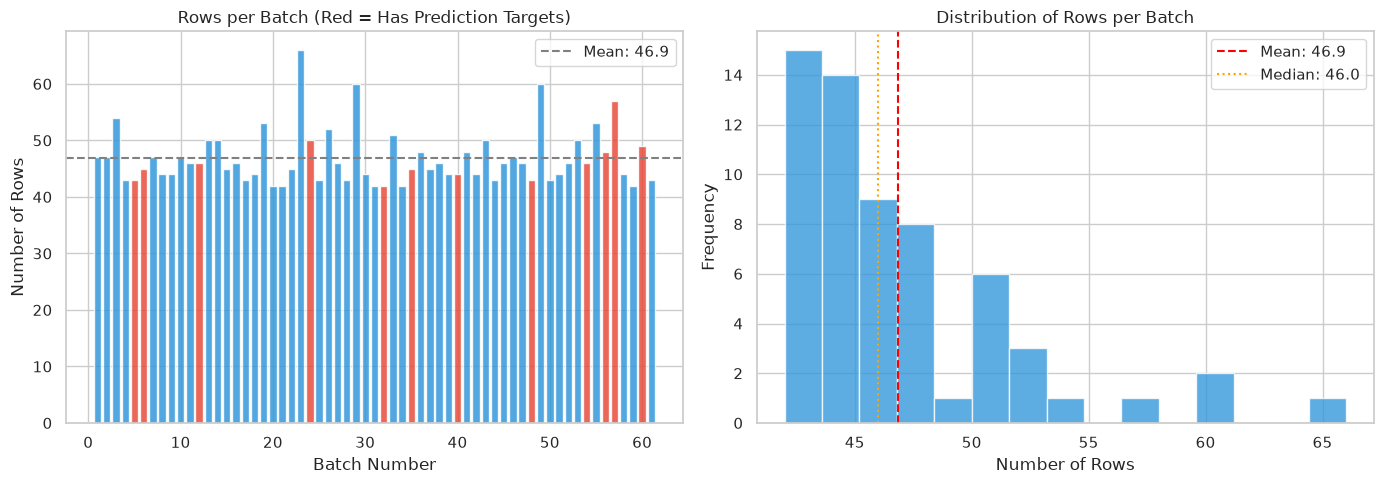

In [22]:
# Distribution of rows per batch
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors = ['#e74c3c' if h else '#3498db' for h in batch_stats['has_predict']]
ax.bar(batch_stats['batch_num'], batch_stats['n_rows'], color=colors, alpha=0.85)
ax.axhline(y=batch_stats['n_rows'].mean(), color='gray', linestyle='--', 
           label=f'Mean: {batch_stats["n_rows"].mean():.1f}')
ax.set_xlabel('Batch Number')
ax.set_ylabel('Number of Rows')
ax.set_title('Rows per Batch (Red = Has Prediction Targets)')
ax.legend()

ax = axes[1]
ax.hist(batch_stats['n_rows'], bins=15, edgecolor='white', color='#3498db', alpha=0.8)
ax.axvline(x=batch_stats['n_rows'].mean(), color='red', linestyle='--', 
           label=f'Mean: {batch_stats["n_rows"].mean():.1f}')
ax.axvline(x=batch_stats['n_rows'].median(), color='orange', linestyle=':', 
           label=f'Median: {batch_stats["n_rows"].median():.1f}')
ax.set_xlabel('Number of Rows')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Rows per Batch')
ax.legend()

plt.tight_layout()
plt.show()

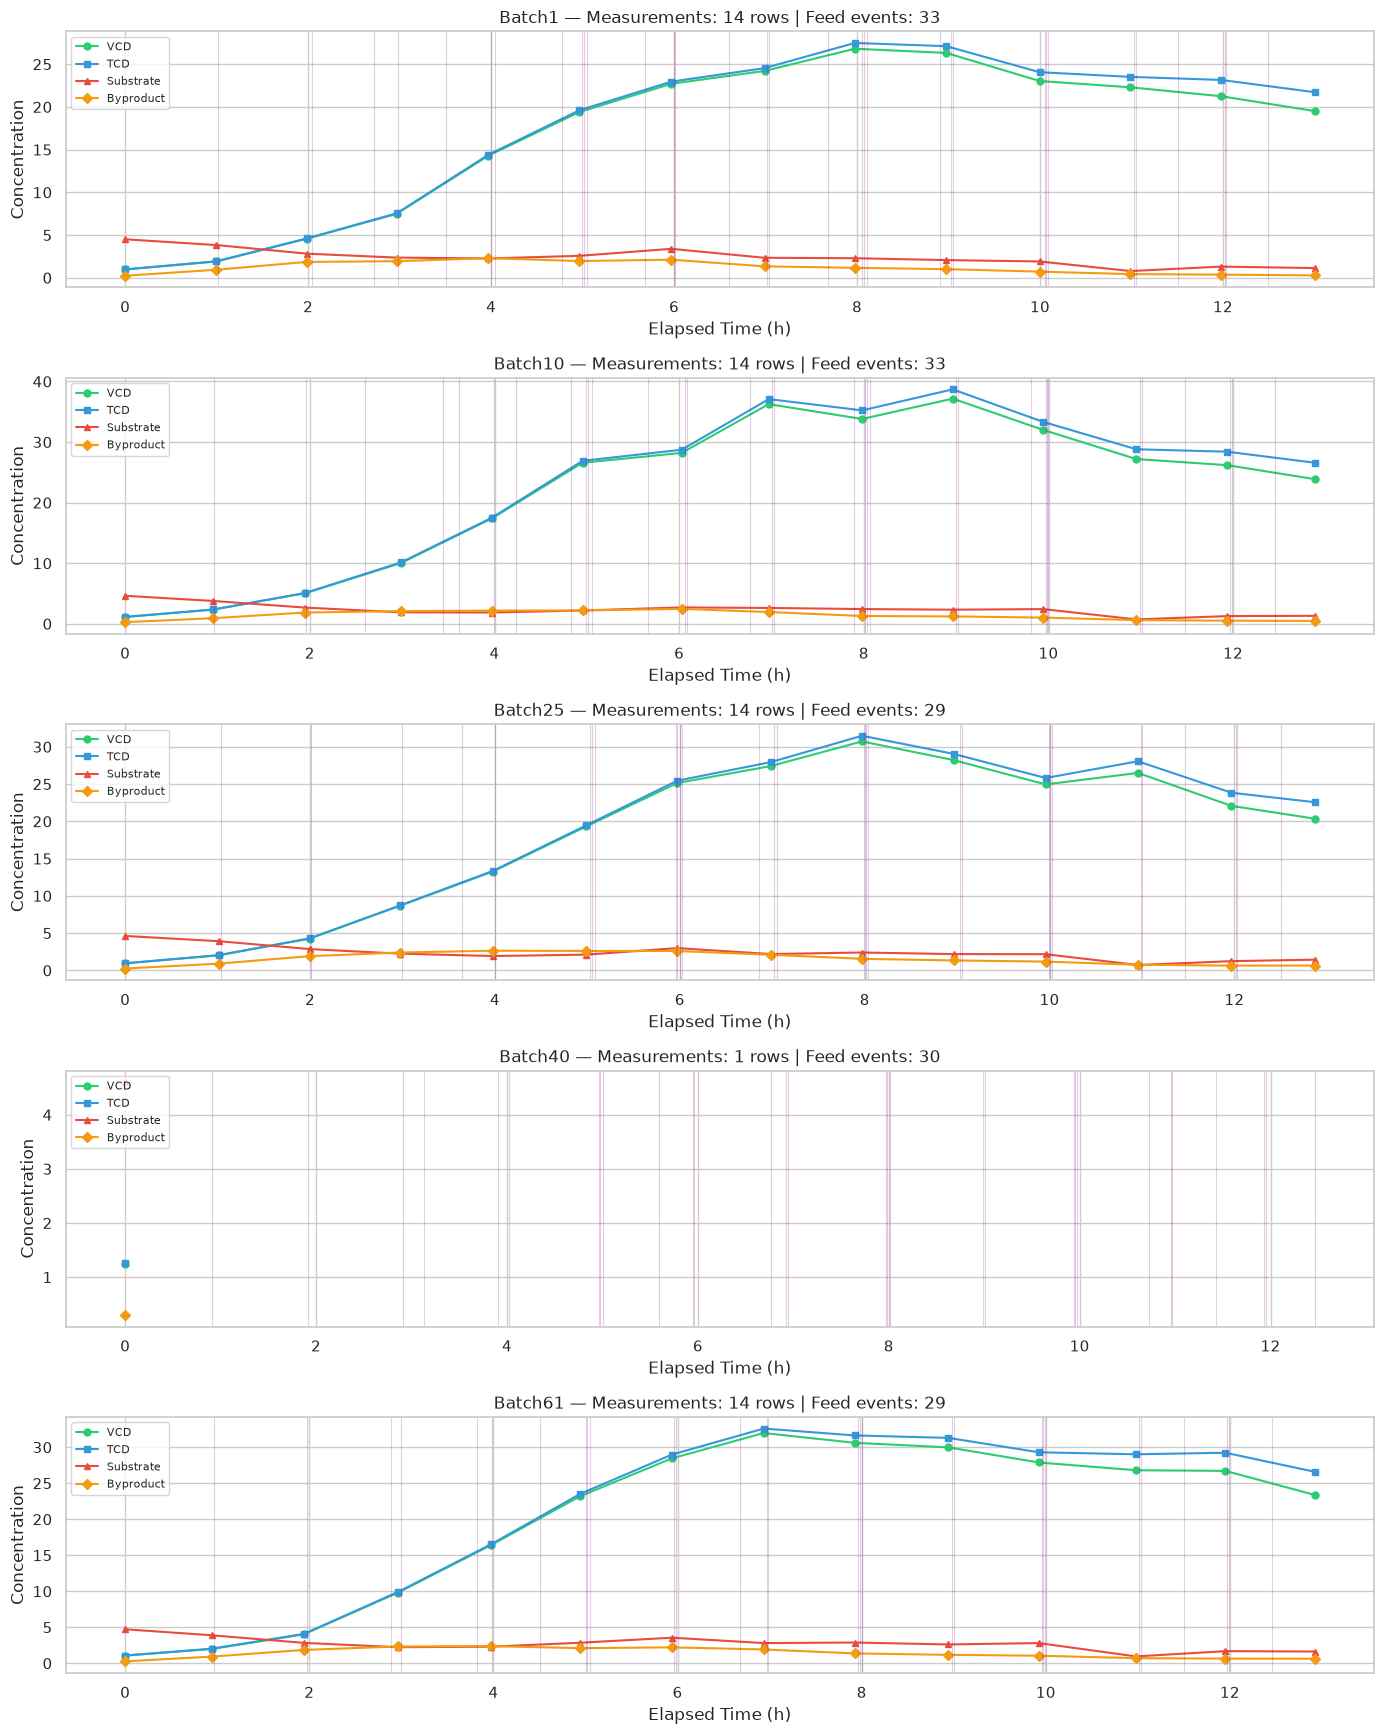

In [23]:
# Plot trajectories for a few example training batches
sample_batches = ['Batch1', 'Batch10', 'Batch25', 'Batch40', 'Batch61']

# Filter to rows that have actual measurements
training_df = df_raw[~predict_mask]

fig, axes = plt.subplots(len(sample_batches), 1, figsize=(14, 3.5 * len(sample_batches)))

for i, batch_id in enumerate(sample_batches):
    batch = training_df[training_df['batch_id'] == batch_id]
    ax = axes[i]
    
    # Measurements with markers
    measured = batch.dropna(subset=['vcd'])
    ax.plot(measured['elapsed_time'], measured['vcd'], 'o-', label='VCD', 
            markersize=5, linewidth=1.5, color='#2ecc71')
    ax.plot(measured['elapsed_time'], measured['tcd'], 's-', label='TCD', 
            markersize=5, linewidth=1.5, color='#3498db')
    ax.plot(measured['elapsed_time'], measured['substrate'], '^-', label='Substrate', 
            markersize=5, linewidth=1.5, color='#e74c3c')
    ax.plot(measured['elapsed_time'], measured['byproduct'], 'D-', label='Byproduct', 
            markersize=5, linewidth=1.5, color='#f39c12')
    
    # Mark feed events (rows where feed data exists)
    feeds = batch.dropna(subset=['feed_substrate', 'feed_b', 'feed_c', 'feed_d'], how='all')
    # Mark feed events on the plot as vertical spans
    for _, feed_row in feeds.iterrows():
        ax.axvline(x=feed_row['elapsed_time'], color='purple', alpha=0.2, linewidth=0.8)
    
    ax.set_title(f'{batch_id} — Measurements: {len(measured)} rows | Feed events: {len(feeds)}')
    ax.set_xlabel('Elapsed Time (h)')
    ax.set_ylabel('Concentration')
    ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

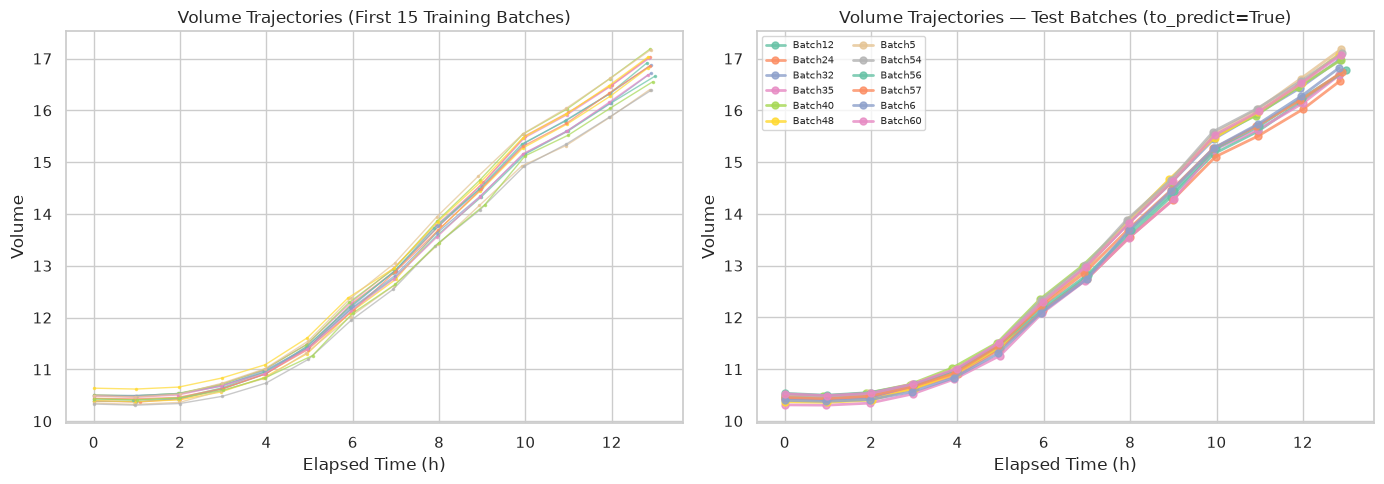

In [24]:
# Volume trajectories for all batches (volume is the only measurement available for ALL rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for batch_id in training_df['batch_id'].unique()[:15]:  # First 15 training batches
    batch = df_raw[df_raw['batch_id'] == batch_id]
    vol_rows = batch.dropna(subset=['volume'])
    ax.plot(vol_rows['elapsed_time'], vol_rows['volume'], marker='.', 
            markersize=3, alpha=0.7, linewidth=1, label=batch_id)
ax.set_xlabel('Elapsed Time (h)')
ax.set_ylabel('Volume')
ax.set_title('Volume Trajectories (First 15 Training Batches)')

ax = axes[1]
predict_batches = sorted(df_raw[predict_mask]['batch_id'].unique())
for batch_id in predict_batches:
    batch = df_raw[df_raw['batch_id'] == batch_id]
    vol_rows = batch.dropna(subset=['volume'])
    ax.plot(vol_rows['elapsed_time'], vol_rows['volume'], 'o-', 
            markersize=5, alpha=0.8, linewidth=2, label=batch_id)
ax.set_xlabel('Elapsed Time (h)')
ax.set_ylabel('Volume')
ax.set_title('Volume Trajectories — Test Batches (to_predict=True)')
ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

---
## 4. Target Variable Distributions

Understanding the distribution and relationships of the 4 target variables (`vcd`, `tcd`, `substrate`, `byproduct`) across all training batches.

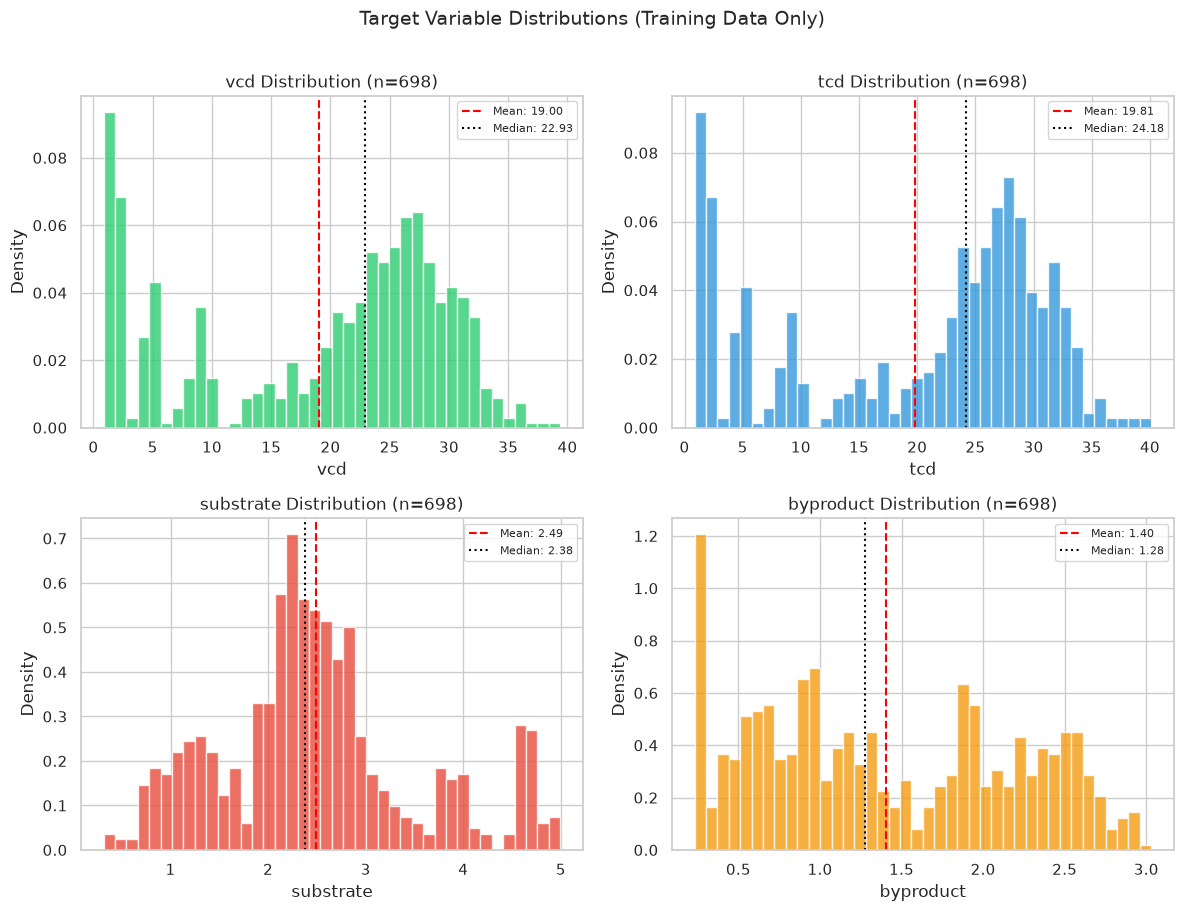

In [25]:
# Distribution of target variables
targets = ['vcd', 'tcd', 'substrate', 'byproduct']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']

for ax, col, color in zip(axes.flat, targets, colors):
    values = df_raw[col].dropna()
    ax.hist(values, bins=40, edgecolor='white', color=color, alpha=0.8, density=True)
    ax.axvline(x=values.mean(), color='red', linestyle='--', label=f'Mean: {values.mean():.2f}')
    ax.axvline(x=values.median(), color='black', linestyle=':', label=f'Median: {values.median():.2f}')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.set_title(f'{col} Distribution (n={len(values):,})')
    ax.legend(fontsize=8)

plt.suptitle('Target Variable Distributions (Training Data Only)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [26]:
print(df_raw[targets].dropna())

            vcd        tcd  substrate  byproduct
0      0.979690   0.985251   4.507188   0.241840
1      1.909271   1.929805   3.830345   0.940785
3      4.574543   4.611517   2.827742   1.860896
6      7.489739   7.545903   2.362482   1.941632
9     14.300371  14.405872   2.263021   2.301048
...         ...        ...        ...        ...
2842  29.976016  31.295039   2.613940   1.171083
2845  27.879677  29.297483   2.803709   1.049627
2849  26.802576  29.016021   0.951758   0.709797
2853  26.713782  29.231672   1.682427   0.650373
2857  23.383673  26.592588   1.632174   0.632185

[698 rows x 4 columns]


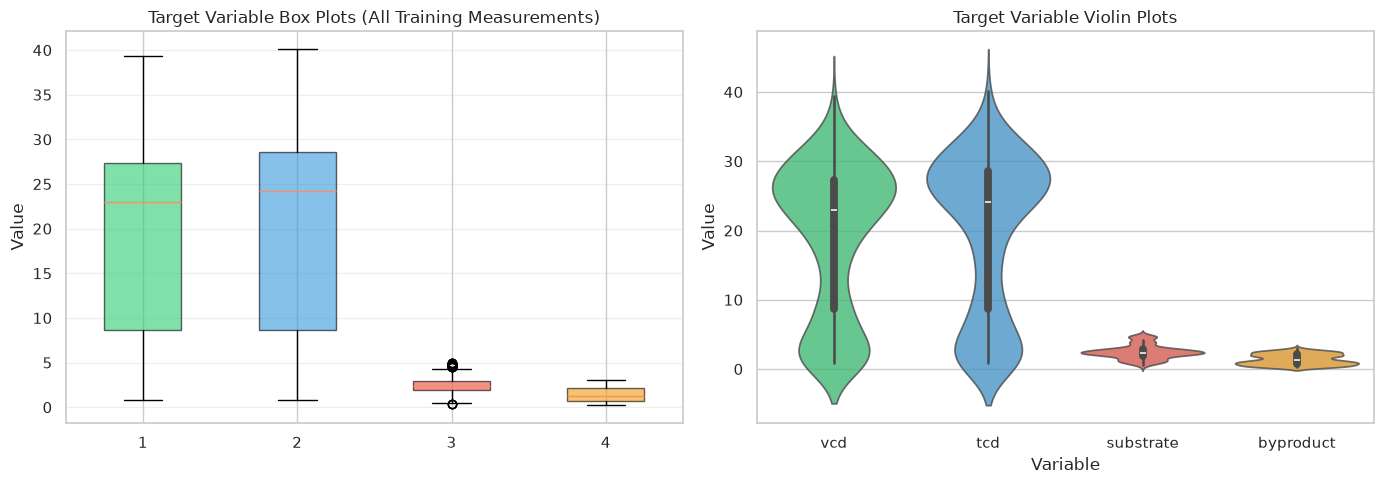

In [27]:
# Box plots of targets to identify outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
target_df = df_raw[targets].dropna()
bp = ax.boxplot([target_df[c] for c in targets], label=targets, patch_artist=True,
                widths=0.5)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_title('Target Variable Box Plots (All Training Measurements)')
ax.set_ylabel('Value')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
# Violin plots
target_melted = target_df.melt(var_name='Variable', value_name='Value')
sns.violinplot(data=target_melted, x='Variable', y='Value', palette=colors, ax=ax, alpha=0.8)
ax.set_title('Target Variable Violin Plots')
ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

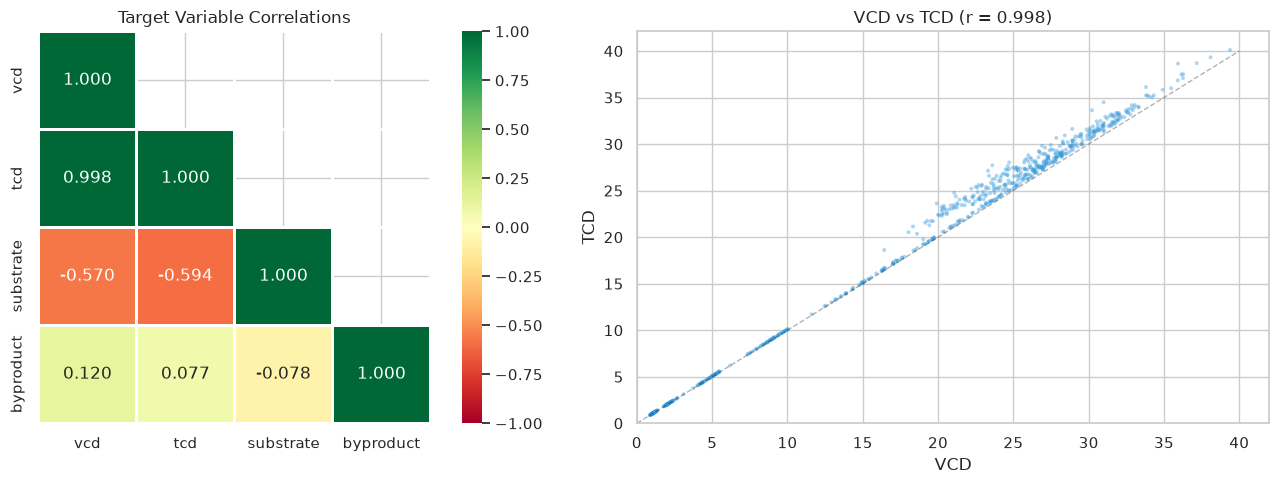


Correlation matrix:
             vcd    tcd  substrate  byproduct
vcd        1.000  0.998     -0.570      0.120
tcd        0.998  1.000     -0.594      0.077
substrate -0.570 -0.594      1.000     -0.078
byproduct  0.120  0.077     -0.078      1.000


In [28]:
# Pairwise relationships between targets
target_df = df_raw[['vcd', 'tcd', 'substrate', 'byproduct']].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Correlation heatmap
ax = axes[0]
corr = target_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.3f', cmap='RdYlGn', 
            vmin=-1, vmax=1, center=0, square=True, ax=ax, linewidths=1)
ax.set_title('Target Variable Correlations')

# Scatter matrix (key pairs)
ax = axes[1]
ax.scatter(target_df['vcd'], target_df['tcd'], alpha=0.4, s=8, c='#3498db', edgecolors='none')
ax.plot([0, 40], [0, 40], 'k--', alpha=0.3, linewidth=1)
ax.set_xlabel('VCD')
ax.set_ylabel('TCD')
ax.set_title(f'VCD vs TCD (r = {corr.loc["vcd", "tcd"]:.3f})')
ax.set_xlim(0, None)
ax.set_ylim(0, None)

plt.tight_layout()
plt.show()

print('\nCorrelation matrix:')
print(corr.round(3))

---
## 5. Feed Input Analysis

The 4 feed columns (`feed_substrate`, `feed_b`, `feed_c`, `feed_d`) appear on separate rows from the measurements. This is a **fed-batch** process where feeds are added intermittently. Understanding the feed schedule and magnitude is crucial for modeling.

In [29]:
# Feed data overview
feed_cols = ['feed_substrate', 'feed_b', 'feed_c', 'feed_d']

print('=== Feed Data Summary ===')
for col in feed_cols:
    vals = df_raw[col].dropna()
    print(f'{col:20s}: {len(vals):5d} non-null | min={vals.min():.6f} | max={vals.max():.6f} | mean={vals.mean():.6f}')

# Which batches have which feeds?
print('\n=== Feeds per Batch (sample) ===')
feed_per_batch = df_raw.groupby('batch_id')[feed_cols].apply(lambda x: x.notnull().sum())
print(feed_per_batch.head(10))

=== Feed Data Summary ===
feed_substrate      :   132 non-null | min=0.050117 | max=0.099265 | mean=0.074470
feed_b              :   732 non-null | min=0.042437 | max=0.969634 | mean=0.547987
feed_c              :   957 non-null | min=0.000768 | max=0.001991 | mean=0.001343
feed_d              :   183 non-null | min=0.010328 | max=0.017477 | mean=0.014665

=== Feeds per Batch (sample) ===
          feed_substrate  feed_b  feed_c  feed_d
batch_id                                        
Batch1                 2      12      16       3
Batch10                2      12      16       3
Batch11                2      12      15       3
Batch12                2      12      15       3
Batch13                3      12      18       3
Batch14                2      12      19       3
Batch15                2      12      14       3
Batch16                2      12      15       3
Batch17                2      12      12       3
Batch18                2      12      13       3


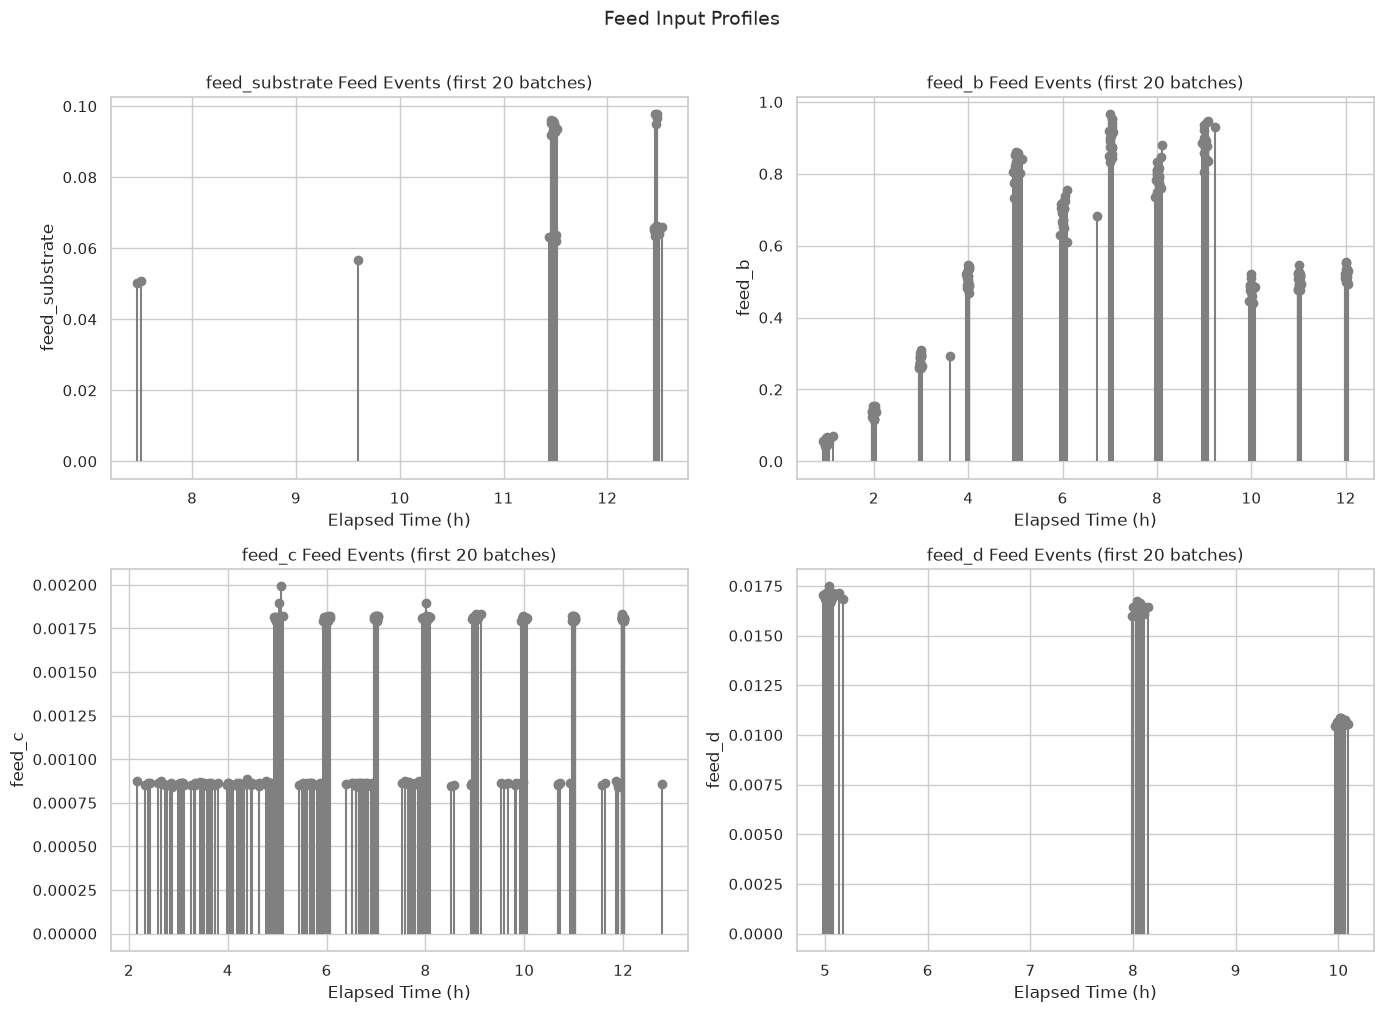

In [30]:
# Feed magnitudes over time
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, feed_cols):
    feed_data = df_raw.dropna(subset=[col])
    for batch_id in feed_data['batch_id'].unique()[:20]:
        batch_feeds = feed_data[feed_data['batch_id'] == batch_id]
        ax.stem(batch_feeds['elapsed_time'], batch_feeds[col], 
                linefmt='grey', markerfmt='o', basefmt=' ')
    ax.set_xlabel('Elapsed Time (h)')
    ax.set_ylabel(col)
    ax.set_title(f'{col} Feed Events (first 20 batches)')

plt.suptitle('Feed Input Profiles', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

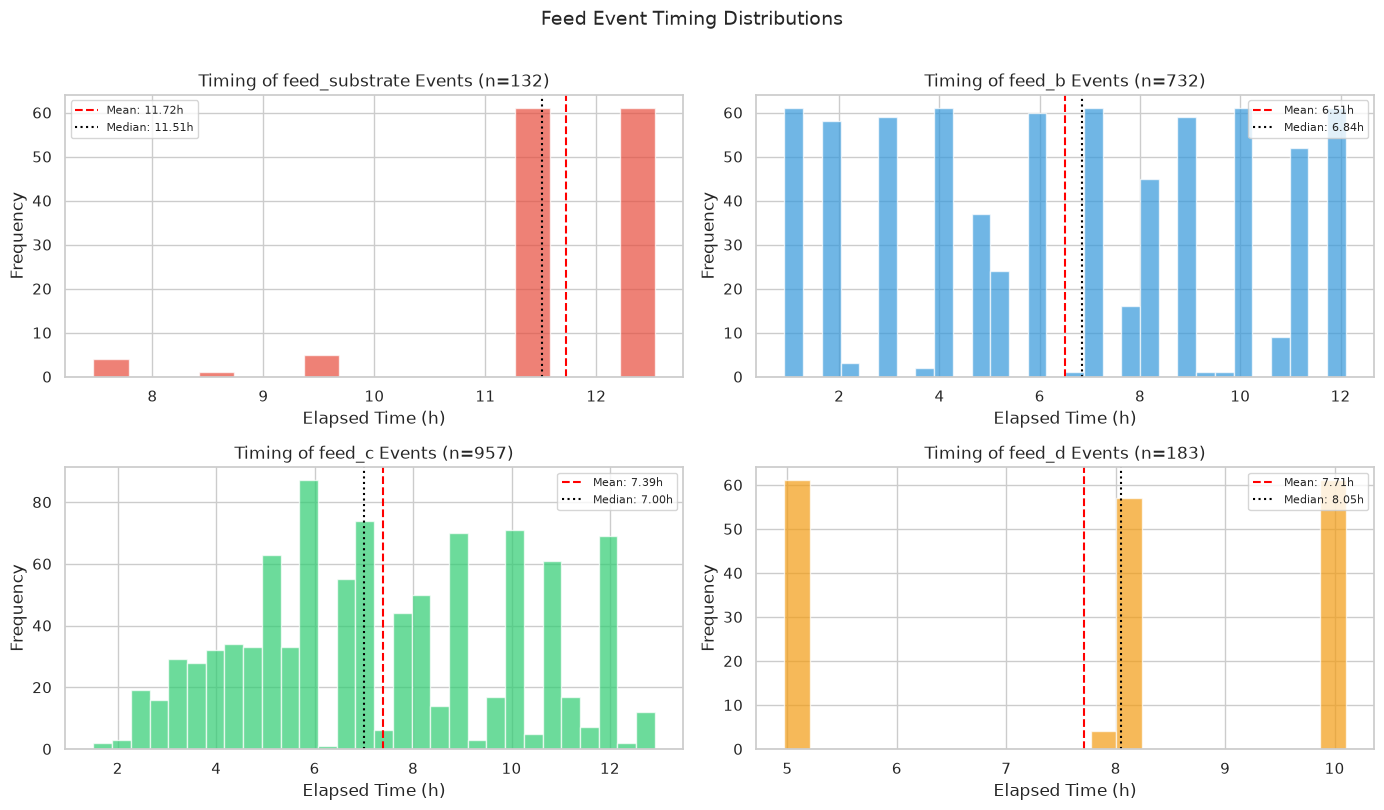

In [31]:
# When do feed events happen relative to the batch duration?
feed_cols = ['feed_substrate', 'feed_b', 'feed_c', 'feed_d']
feed_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col, color in zip(axes.flat, feed_cols, feed_colors):
    feed_data = df_raw.dropna(subset=[col])
    times = feed_data['elapsed_time']
    
    # Adaptive bin count: fewer bins for sparse feeds
    n_bins = min(30, max(10, len(times) // 8))
    
    ax.hist(times, bins=n_bins, edgecolor='white', color=color, alpha=0.7)
    ax.axvline(x=times.mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'Mean: {times.mean():.2f}h')
    ax.axvline(x=times.median(), color='black', linestyle=':', linewidth=1.5,
               label=f'Median: {times.median():.2f}h')
    ax.set_xlabel('Elapsed Time (h)')
    ax.set_ylabel('Frequency')
    ax.set_title(f'Timing of {col} Events (n={len(times)})')
    ax.legend(fontsize=8)

plt.suptitle('Feed Event Timing Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

---
## 6. Time-Series Patterns

Let's look at how the target variables evolve over time across batches — do they follow consistent trajectories?

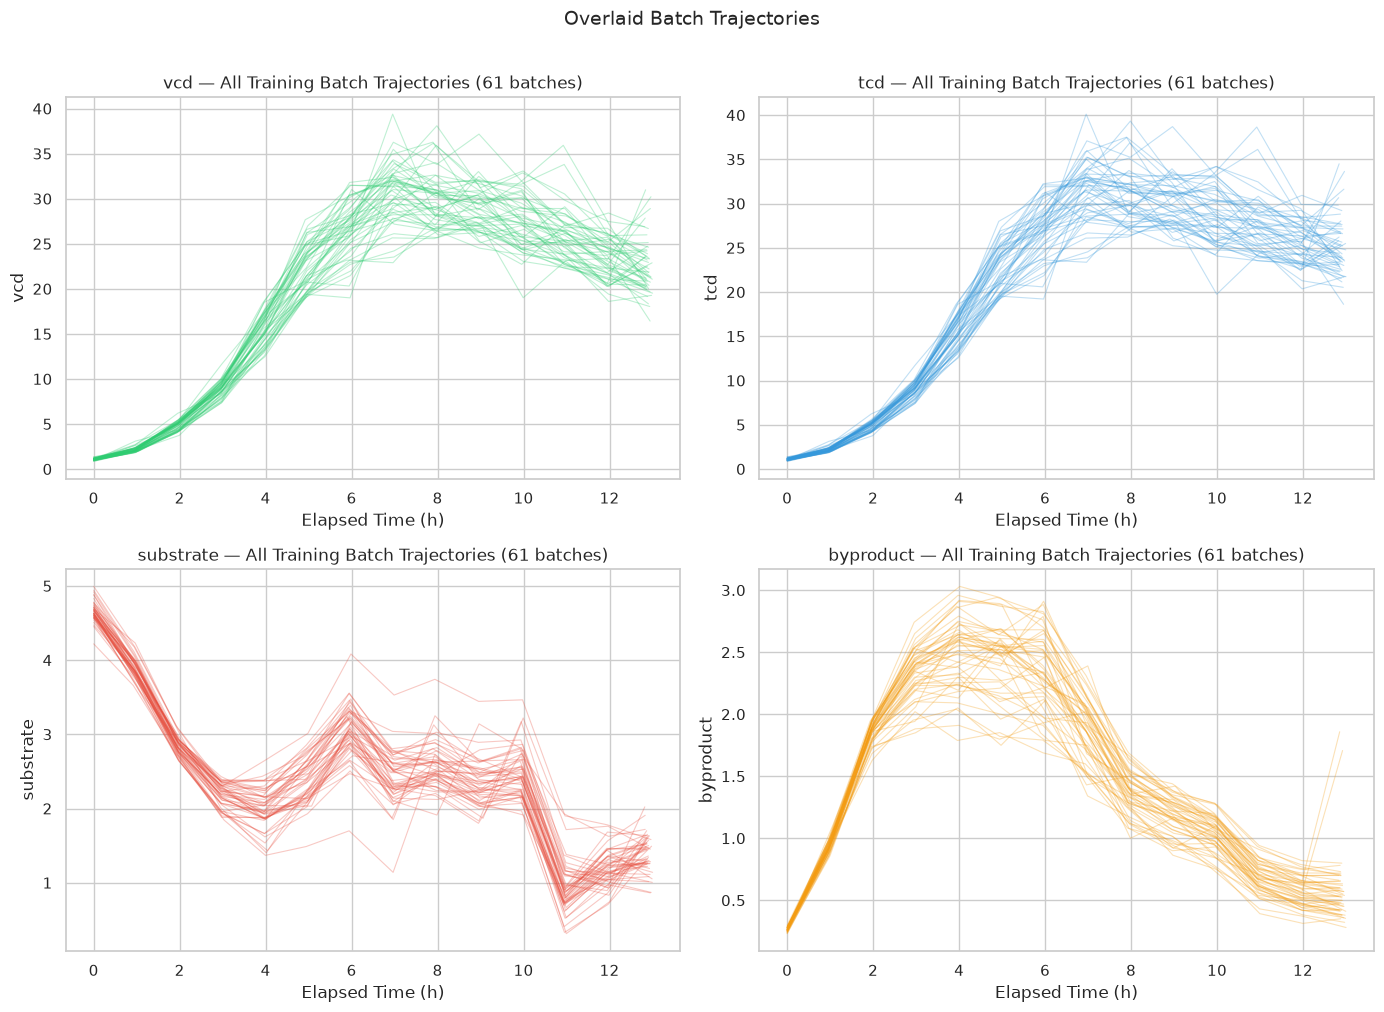

In [32]:
# Overlay all batch trajectories for each target
measured_df = df_raw.dropna(subset=['vcd'])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col, color in zip(axes.flat, targets, colors):
    for batch_id in measured_df['batch_id'].unique():
        batch = measured_df[measured_df['batch_id'] == batch_id]
        ax.plot(batch['elapsed_time'], batch[col], alpha=0.3, linewidth=0.8, color=color)
    ax.set_xlabel('Elapsed Time (h)')
    ax.set_ylabel(col)
    ax.set_title(f'{col} — All Training Batch Trajectories ({measured_df["batch_id"].nunique()} batches)')

plt.suptitle('Overlaid Batch Trajectories', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

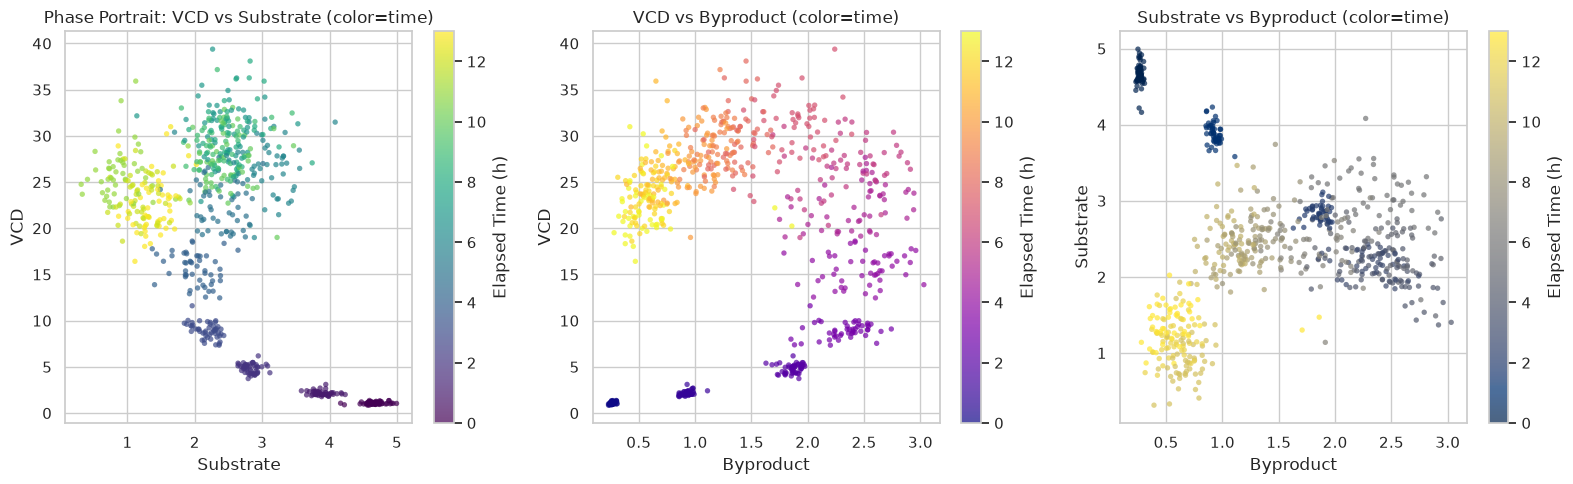

In [33]:
# Phase portrait: VCD vs Substrate colored by batch time
measured_df = df_raw.dropna(subset=['vcd', 'substrate'])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# VCD vs Substrate, colored by time
ax = axes[0]
sc = ax.scatter(measured_df['substrate'], measured_df['vcd'], 
                c=measured_df['elapsed_time'], cmap='viridis', s=15, alpha=0.7, edgecolors='none')
ax.set_xlabel('Substrate')
ax.set_ylabel('VCD')
ax.set_title('Phase Portrait: VCD vs Substrate (color=time)')
plt.colorbar(sc, ax=ax, label='Elapsed Time (h)')

# VCD vs Byproduct
ax = axes[1]
sc = ax.scatter(measured_df['byproduct'], measured_df['vcd'], 
                c=measured_df['elapsed_time'], cmap='plasma', s=15, alpha=0.7, edgecolors='none')
ax.set_xlabel('Byproduct')
ax.set_ylabel('VCD')
ax.set_title('VCD vs Byproduct (color=time)')
plt.colorbar(sc, ax=ax, label='Elapsed Time (h)')

# Substrate vs Byproduct
ax = axes[2]
sc = ax.scatter(measured_df['byproduct'], measured_df['substrate'], 
                c=measured_df['elapsed_time'], cmap='cividis', s=15, alpha=0.7, edgecolors='none')
ax.set_xlabel('Byproduct')
ax.set_ylabel('Substrate')
ax.set_title('Substrate vs Byproduct (color=time)')
plt.colorbar(sc, ax=ax, label='Elapsed Time (h)')

plt.tight_layout()
plt.show()

---
## 7. Volume & Time Analysis

Volume is the only measurement available in prediction rows. Let's explore its relationship with the targets and time.

Merged rows with volume: 698
Max volume time difference: 0.000h


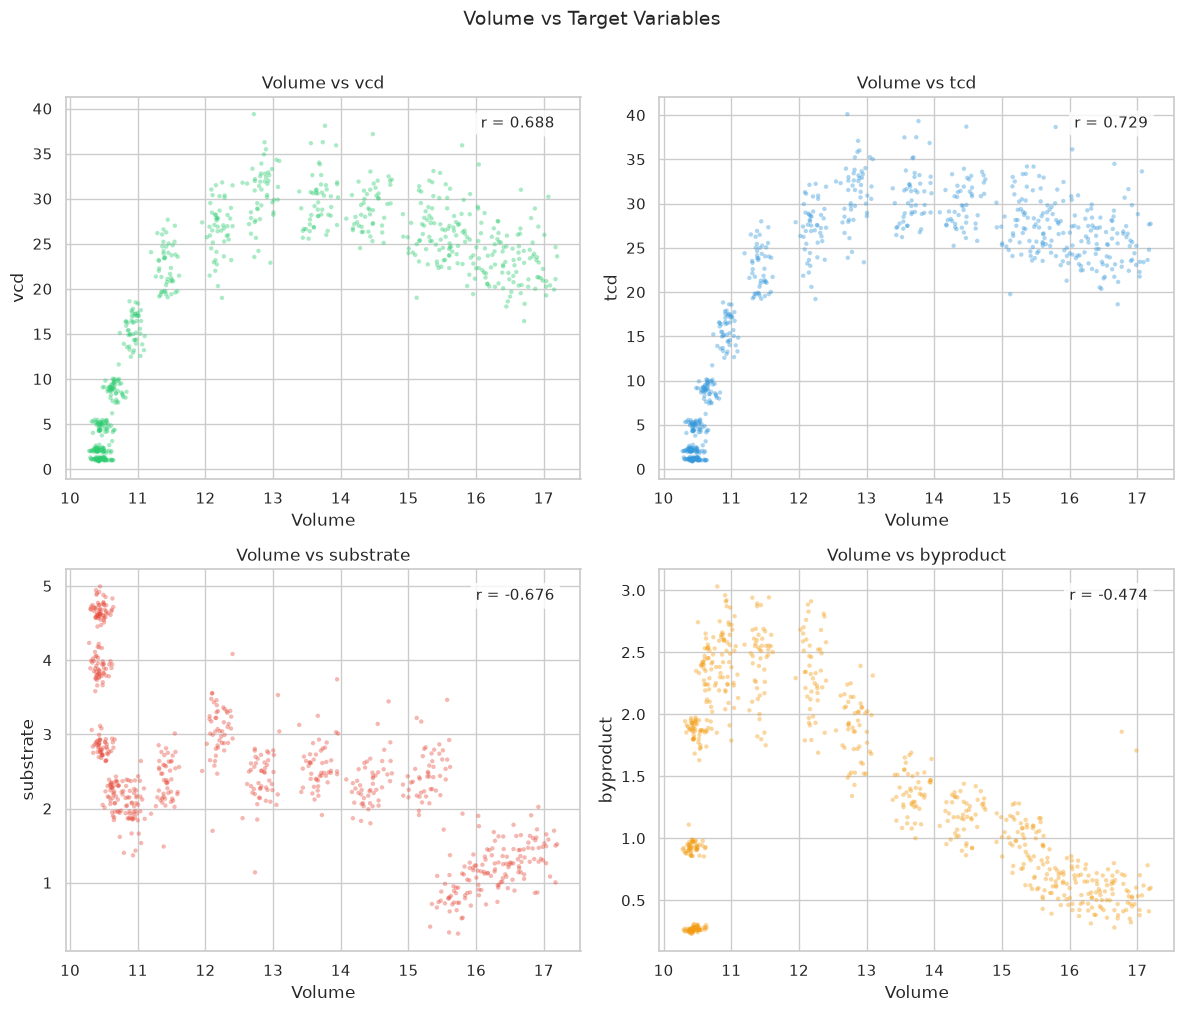

In [34]:
# Merge volume with measurements for training rows
# Since volume is on separate rows from measurements, we need to forward-fill or interpolate
train_df = df_raw[~predict_mask].copy()

# Get rows with measurements and their corresponding volume
measured_rows = train_df.dropna(subset=['vcd']).copy()
volume_rows = train_df.dropna(subset=['volume']).copy()

# For each measured row, find the closest volume measurement in the same batch
def merge_volume(measured, volumes):
    """Merge measured data with closest volume from the same batch."""
    merged = []
    for batch_id in measured['batch_id'].unique():
        b_measured = measured[measured['batch_id'] == batch_id]
        b_volumes = volumes[volumes['batch_id'] == batch_id]
        if len(b_volumes) == 0:
            continue
        for _, m_row in b_measured.iterrows():
            # Find closest volume row in time
            time_diffs = (b_volumes['elapsed_time'] - m_row['elapsed_time']).abs()
            closest_idx = time_diffs.idxmin()
            merged.append({
                'batch_id': batch_id,
                'elapsed_time': m_row['elapsed_time'],
                'vcd': m_row['vcd'],
                'tcd': m_row['tcd'],
                'substrate': m_row['substrate'],
                'byproduct': m_row['byproduct'],
                'volume': b_volumes.loc[closest_idx, 'volume'],
                'volume_time_diff': time_diffs.min()
            })
    return pd.DataFrame(merged)

merged_df = merge_volume(measured_rows, volume_rows)
print(f'Merged rows with volume: {len(merged_df)}')
print(f'Max volume time difference: {merged_df["volume_time_diff"].max():.3f}h')

# Plot volume vs targets
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, col, color in zip(axes.flat, targets, colors):
    ax.scatter(merged_df['volume'], merged_df[col], alpha=0.4, s=10, 
              c=color, edgecolors='none')
    ax.set_xlabel('Volume')
    ax.set_ylabel(col)
    ax.set_title(f'Volume vs {col}')
    # Add correlation
    r = merged_df['volume'].corr(merged_df[col])
    ax.text(0.95, 0.95, f'r = {r:.3f}', transform=ax.transAxes, 
            ha='right', va='top', fontsize=11, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('Volume vs Target Variables', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

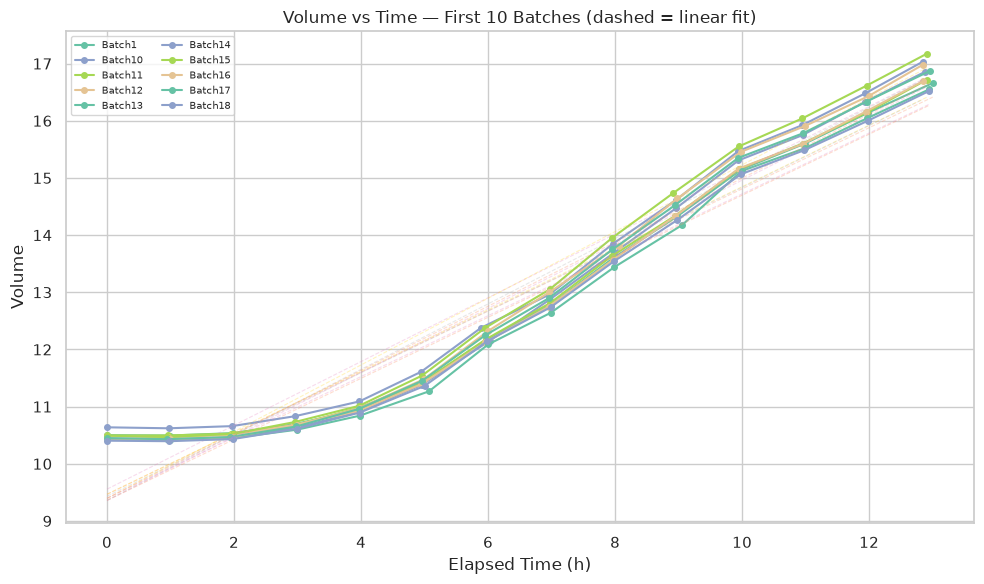

In [35]:
# Volume vs elapsed time — check how linear it is
fig, ax = plt.subplots(figsize=(10, 6))

for batch_id in sorted(df_raw['batch_id'].unique())[:10]:
    batch_vol = df_raw[df_raw['batch_id'] == batch_id].dropna(subset=['volume'])
    ax.plot(batch_vol['elapsed_time'], batch_vol['volume'], 'o-', 
            markersize=4, label=batch_id, linewidth=1.5)
    # Fit a line
    if len(batch_vol) > 2:
        coeffs = np.polyfit(batch_vol['elapsed_time'], batch_vol['volume'], 1)
        ax.plot(batch_vol['elapsed_time'], np.polyval(coeffs, batch_vol['elapsed_time']), 
                '--', alpha=0.3, linewidth=0.8)

ax.set_xlabel('Elapsed Time (h)')
ax.set_ylabel('Volume')
ax.set_title('Volume vs Time — First 10 Batches (dashed = linear fit)')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

---
## 8. Summary & Modeling Implications

### Key Findings

1. **Sparse interleaved structure**: Measurements and feed events are on separate rows — preprocessing must merge or interpolate these into a consistent time grid.

2. **12 test batches**: `Batch5, Batch6, Batch12, Batch24, Batch32, Batch35, Batch40, Batch48, Batch54, Batch56, Batch57, Batch60` have `to_predict=True` rows with only `elapsed_time` and `volume` known.

3. **Volume is the key connector**: It's the only variable available in both training and prediction rows. Volume grows near-linearly with time (fed-batch dilution).

4. **Target correlations**: VCD and TCD are strongly positively correlated. Substrate decreases over time as cells consume it; byproduct increases as a metabolic waste product.

5. **Feed complexity**: Four feed streams (`feed_substrate`, `feed_b`, `feed_c`, `feed_d`) at irregular intervals. Only `feed_b` and `feed_c` have substantial data (732 and 957 events). `feed_d` is very rare (183 events).

### Modeling Approaches to Consider

- **Interpolation**: Align measurements and feeds onto a regular time grid per batch (forward-fill feeds, interpolate volume)
- **ODE-based / mechanistic models**: Bioreactor dynamics have known differential equation forms (Monod kinetics)
- **Sequence models**: LSTM/GRU treating each batch as a time series with feed inputs
- **Hybrid models**: Combine mechanistic ODEs with learned components